### Results / Model / Prediction

This cell documents the traffic scene object detection experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

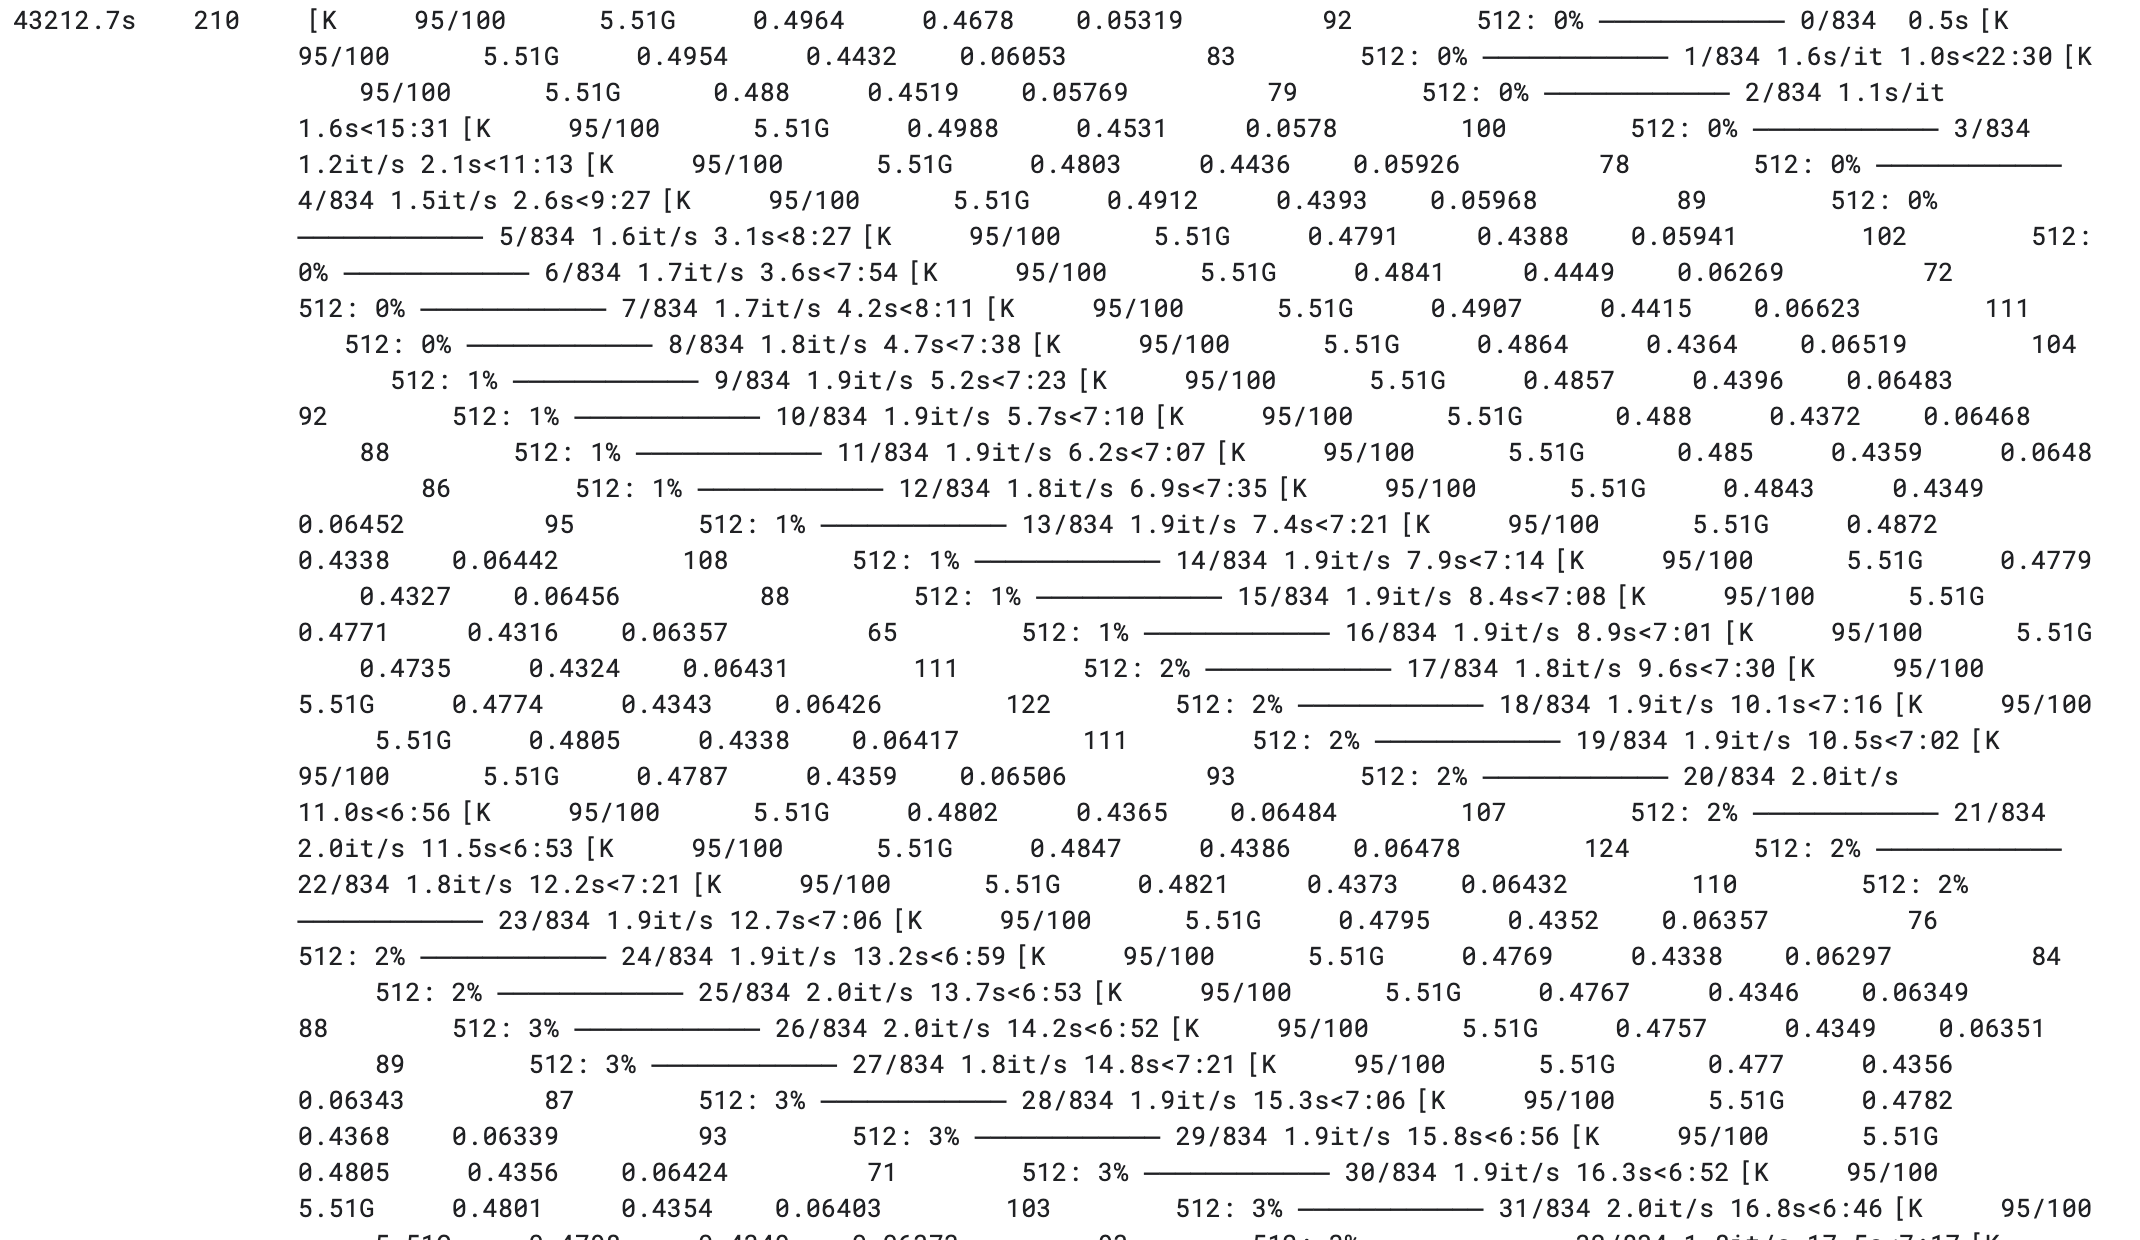

In [ ]:
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
# Note on Load. Refer to the archived source for the detailed original comment.
classes_path = "/kaggle/input/datasets/fdiiiiii/d2-city-yolo/dataset/labels/classes.txt"
with open(classes_path, 'r') as f:
    class_names = [line.strip() for line in f.readlines()]

nc = len(class_names)
names = {i: name for i, name in enumerate(class_names)}

print(f"检测到 {nc} 个类别:")
for i, name in names.items():
    print(f"  {i}: {name}")

# 写入 d2-city.yaml
yaml_content = f"""
# D2-City dataset configuration
path: /kaggle/input/datasets/fdiiiiii/d2-city-yolo/dataset
train: /kaggle/input/datasets/fdiiiiii/d2-city-yolo/dataset/images/train
val: //kaggle/input/datasets/fdiiiiii/d2-city-yolo/dataset/images/val

nc: {nc}
names: {names}
"""

with open("/kaggle/working/d2-city.yaml", "w") as f:
    f.write(yaml_content)

print("已生成 /kaggle/working/d2-city.yaml")

In [1]:
%%writefile train_exp.py
# train_exp.py 

import os
import sys
from ultralytics import YOLO

"""
Part II: YOLO26s - 更换为更大模型并加载 COCO 预训练权重
"""

def experiment_1():
    """实验1: YOLO26s + pretrained (640px)"""
    model = YOLO("yolo26s.pt")          # 加载预训练权重
    
    model.train(
        data="./d2-city.yaml",
        epochs=150,
        patience=50,
        cache=True,        
        imgsz=640,
        batch=16,          # 在显存允许下batch 越大，GPU 利用率越高。对于 26s，若开启 AMP，batch 可尝试 16。
        amp=True,
        rect=True,         # 矩形训练减少填充，提高训练效率
        project=".",            # 保存根目录
        name="exp1"             # 子目录
    )
    
    metrics = model.val()
    print(f"Exp1 mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp1 mAP50: {metrics.box.map50:.4f}")

"""
Part III: YOLO26n + 预训练权重 + 更高分辨率且数据增强
"""

def experiment_2():
    """实验2: YOLO26n + pretrained + 高分辨率960px + 数据增强"""
    model = YOLO("yolo26n.pt")
    
    model.train(
        data="./d2-city.yaml",
        epochs=100,
        cache=False,        # Kaggle 关闭缓存
        imgsz=960,
        batch=10,
        rect=True,          # 矩形训练，减少填充
        mosaic=1.0,
        mixup=0.5,
        copy_paste=0.5,
        hsv_h=0.02,
        hsv_s=0.8,
        hsv_v=0.4,
        amp=False,
        project=".",
        name="exp2"
    )
    metrics = model.val()
    print(f"Exp2 mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp2 mAP50: {metrics.box.map50:.4f}")

"""
Part IV: YOLO26m + 预训练权重 + 更高分辨率且数据增强、优化器等
"""

def experiment_3():
    """
    实验3: 激进方案 —— 更大模型 + 高分辨率 + 全面优化
    - 模型: YOLO26m (参数量 ~25M)
    - 分辨率: 960px
    - 优化器: AdamW + 余弦退火
    - 训练轮数: 150, 早停 patience=50
    - 增强: mosaic, mixup, copy_paste, flipud, degrees, scale
    - 标签平滑: 0.1
    - 验证时启用 TTA
    """
    model = YOLO("yolo26m.pt")          # 最大的 YOLO26 模型
    
    model.train(
        data="./d2-city.yaml",
        cache=True,
        epochs=150,
        patience=50,
        imgsz=800,           # 降低至 800，平衡精度与速度
        batch=8,             # 开启AMP
        rect=True,
        optimizer='AdamW',
        lr0=0.001,
        cos_lr=True,
        label_smoothing=0.1,
        mosaic=0.8,
        mixup=0.4,
        copy_paste=0.5,
        hsv_h=0.02,
        hsv_s=0.8,
        hsv_v=0.4,
        flipud=0.5,
        degrees=5.0,
        scale=0.5,
        amp=True,               # 若显存不足可开启 amp=True 节省显存
        project=".",
        name="exp3"
    )
    
    # Note on Validation. Refer to the archived source for the detailed original comment.
    metrics = model.val(augment=True)
    print(f"Exp3 mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp3 mAP50: {metrics.box.map50:.4f}")

"""
Part V: YOLOv11n - 速度与效率对照实验
"""

def experiment_4():
    """实验4: YOLOv11n - 速度与效率对照实验"""
    model = YOLO("yolo11n.pt")  # 或 yolo11s.pt
    
    model.train(
        data="./d2-city.yaml",
        epochs=150,             # 与实验2/3保持一致
        patience=50,
        cache=True,
        imgsz=800,              # 从标准分辨率开始
        batch=16,
        amp=True,               # 启用混合精度训练
        rect=True,
        project=".",
        name="exp4"
    )
    
    metrics = model.val()
    print(f"Exp4 (YOLOv11n) mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp4 (YOLOv11n) mAP50: {metrics.box.map50:.4f}")

"""
Part VI: RT-DETR - Transformer 架构实验
"""

def experiment_5():
    """实验5: RT-DETR-L 在 D2-City 数据集上的表现"""
    from ultralytics import RTDETR

    # Note on Model, Performance, Use. Refer to the archived source for the detailed original comment.
    model = RTDETR("rtdetr-l.pt")

    model.train(
        data="./d2-city.yaml",
        epochs=100,
        # patience=20,
        imgsz=512,
        batch=12,            # Transformer 模型通常更耗显存，建议从较小的 batch size 开始
        amp=True,
        cache=True,                 # 缓存图像到内存/显存，加速 IO
        workers=8,                  # 增加数据加载线程
        freeze=10,                  # 冻结骨干网络前 10 层（减少可训练参数）
        save_period=10,             # 每 10 轮保存检查点（满足断点需求）
        project=".",
        name="exp5"
    )

    metrics = model.val()
    print(f"Exp5 (RT-DETR-L) mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp5 (RT-DETR-L) mAP50: {metrics.box.map50:.4f}")

if __name__ == "__main__":
    # Note on Experiment, Parameters. Refer to the archived source for the detailed original comment.
    # Note on Experiment, Run. Refer to the archived source for the detailed original comment.
    if len(sys.argv) > 1:
        if sys.argv[1] == "2":
            experiment_2()
        elif sys.argv[1] == "3":
            experiment_3()
        elif sys.argv[1] == "4":
            experiment_4()
        elif sys.argv[1] == "5":
            experiment_5()
        else:
            print(f"未知参数: {sys.argv[1]}, 使用默认实验1")
            experiment_1()
    else:
        experiment_1()

Overwriting train_exp.py


In [2]:
!pip install ultralytics

In [ ]:
# Note on Experiment, Run. Refer to the archived source for the detailed original comment.
!python train_exp.py 5

### Results / Prediction / Run

This cell documents the traffic scene object detection experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

```text
Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.7it/s 8.6s
43122.3s	205	 all       1000       8608        0.52      0.445      0.423      0.242
```



0: 512x512 5 cars, 4 buss, 275.7ms
1: 512x512 6 cars, 3 vans, 7 trucks, 5 persons, 8 open-tricycles, 4 closed-tricycles, 4 forklifts, 275.7ms
2: 512x512 7 cars, 1 truck, 275.7ms
3: 512x512 13 cars, 2 vans, 2 trucks, 275.7ms
4: 512x512 7 cars, 1 truck, 275.7ms
5: 512x512 8 cars, 275.7ms
6: 512x512 9 cars, 1 van, 1 bus, 275.7ms
7: 512x512 7 cars, 1 van, 3 persons, 275.7ms
Speed: 0.9ms preprocess, 275.7ms inference, 0.0ms postprocess per image at shape (1, 3, 512, 512)
预测图像: 11399.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11661.jpg


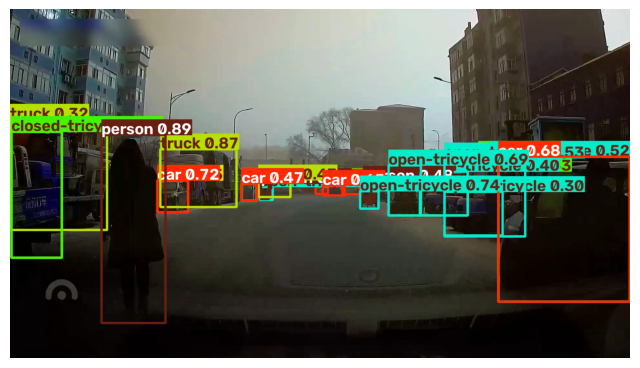

预测图像: 11737.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11301.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11908.jpg


<Figure size 800x600 with 1 Axes>

... (2 outputs left out)

预测图像: 11614.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11618.jpg


<Figure size 800x600 with 1 Axes>

In [4]:
from ultralytics import YOLO
import os
import random
import matplotlib.pyplot as plt

# Note on Model, Training, Load. Refer to the archived source for the detailed original comment.
model = YOLO("/Users/dubby/Desktop/驭风计划/深度学习/作业/实验5-滴滴出行交通场景目标检测/rtdetr_results/runs/detect/exp5/weights/best.pt")  # 或 last.pt

# Note on Testing, Image. Refer to the archived source for the detailed original comment.
test_img_dir = "/Users/dubby/Desktop/驭风计划/深度学习/作业/实验5-滴滴出行交通场景目标检测/data/images/test"

# 随机选8个编号 (11000~11999)
indices = random.sample(range(11000, 12000), 8)
test_img_files = [os.path.join(test_img_dir, f"{idx}.jpg") for idx in indices]

# Note on Prediction. Refer to the archived source for the detailed original comment.
results = model(test_img_files)

# Note on Results, Prediction. Refer to the archived source for the detailed original comment.
for i, (file, result) in enumerate(zip(test_img_files, results)):
    print(f"预测图像: {os.path.basename(file)}")
    
    # Note on Image. Refer to the archived source for the detailed original comment.
    annotated_img = result.plot()   # BGR -> RGB 自动转换
    
    # 显示在单元格中
    plt.figure(figsize=(8, 6))
    plt.imshow(annotated_img)
    plt.axis('off')
    plt.show()